# Week 4 Capstone — Predicting Internship Selection Outcomes

## Objective
To build a Machine Learning model that predicts internship selection outcomes using applicant information.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import pandas as pd

df = pd.read_csv('applicants_cleaned.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (100, 7)


,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Anjali Das,applicant2@example.com,9876510001,Web Development,Not Specified,2026-05-12,Under Review
1,Sravani Rao,applicant3@example.com,9876510002,Web Development,Andhra University,2026-05-15,Under Review
2,Ramya Pulugurtha,applicant4@example.com,9876510003,Web Development,ABC University,2026-05-13,Under Review
3,Deepika Singh,applicant5@example.com,9876510004,Web Development,Andhra University,2026-05-13,Under Review
4,Sravani Rao,applicant6@example.com,9876510005,AI,ABC University,2026-05-15,Under Review


In [ ]:
import numpy as np

# Make random values reproducible
np.random.seed(42)

# 1. Number of skills listed
df['num_skills_listed'] = np.random.randint(1, 9, size=len(df))

# 2. Whether applicant has a portfolio
df['has_portfolio'] = np.random.choice(
    ['Yes', 'No'], size=len(df), p=[0.4, 0.6]
)

# 3. Previous hackathon participation
df['prior_hackathon_participation'] = np.random.choice(
    ['Yes', 'No'], size=len(df), p=[0.3, 0.7]
)

# 4. Statement quality score
df['statement_quality_score'] = np.random.randint(
    1, 11, size=len(df)
)

print("Four new features added successfully!")

In [5]:
df.head()

,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Anjali Das,applicant2@example.com,9876510001,Web Development,Not Specified,2026-05-12,Under Review
1,Sravani Rao,applicant3@example.com,9876510002,Web Development,Andhra University,2026-05-15,Under Review
2,Ramya Pulugurtha,applicant4@example.com,9876510003,Web Development,ABC University,2026-05-13,Under Review
3,Deepika Singh,applicant5@example.com,9876510004,Web Development,Andhra University,2026-05-13,Under Review
4,Sravani Rao,applicant6@example.com,9876510005,AI,ABC University,2026-05-15,Under Review


Data Transparency Note

The four newly added features are simulated using Python's random functions. They are not actual historical applicant information. In a real internship selection system, these details should be collected directly from applicant applications

In [ ]:
# Convert Yes/No into 1/0

df['has_portfolio'] = df['has_portfolio'].map({
    'Yes': 1,
    'No': 0
})

df['prior_hackathon_participation'] = df['prior_hackathon_participation'].map({
    'Yes': 1,
    'No': 0
})

print("Yes/No columns converted successfully!")

In [6]:
# Create target column

df['target'] = df['Status'].apply(
    lambda x: 1 if x == 'Selected' else 0
)

# Remove applicants whose status is Under Review
df_model = df[df['Status'] != 'Under Review'].copy()

print("Target column created successfully!")

print(df_model['target'].value_counts())

Target column created successfully!
target
1    25
0    14
Name: count, dtype: int64


In [7]:
df_model[['Status', 'target']].head(10)

,Status,target
5,Selected,1
7,Selected,1
10,Selected,1
11,Selected,1
12,Selected,1
15,Selected,1
17,Selected,1
18,Selected,1
19,Selected,1
20,Selected,1


In [8]:
# Convert Domain Applied into numerical columns

df_model = pd.get_dummies(
    df_model,
    columns=['Domain Applied'],
    drop_first=True
)

print("One-Hot Encoding completed successfully!")

df_model.head()

One-Hot Encoding completed successfully!


,Applicant Name,Email,Phone,University,Application Date,Status,target,Domain Applied_Cloud Computing,Domain Applied_Cyber Security,Domain Applied_Data Science,Domain Applied_Web Development
5,Vikram Reddy,applicant7@example.com,9876510006,ABC University,2026-05-15,Selected,1,False,False,False,True
7,Sneha Reddy,applicant9@example.com,9876510008,BABA Institute,2026-05-14,Selected,1,False,False,False,False
10,Sneha Reddy,applicant13@example.com,9876510012,Not Specified,2026-05-13,Selected,1,False,False,False,True
11,Sneha Reddy,applicant14@example.com,9876510013,BABA Institute,2026-05-15,Selected,1,False,False,True,False
12,Sai Krishna,applicant15@example.com,9876510014,XYZ College,2026-05-13,Selected,1,True,False,False,False


In [9]:
# Select final features

feature_columns = [
    'num_skills_listed',
    'has_portfolio',
    'prior_hackathon_participation',
    'statement_quality_score'
] + [
    col for col in df_model.columns
    if col.startswith('Domain Applied_')
]

# Input features
X = df_model[feature_columns]

# Target column
y = df_model['target']

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

KeyError: "['num_skills_listed', 'has_portfolio', 'prior_hackathon_participation', 'statement_quality_score'] not in index"

In [10]:
# Recreate df_model using the updated dataset

df_model = df[df['Status'] != 'Under Review'].copy()

# Apply One-Hot Encoding again
df_model = pd.get_dummies(
    df_model,
    columns=['Domain Applied'],
    drop_first=True
)

print("Dataset rebuilt successfully!")
print(df_model.columns.tolist())

Dataset rebuilt successfully!
['Applicant Name', 'Email', 'Phone', 'University', 'Application Date', 'Status', 'target', 'Domain Applied_Cloud Computing', 'Domain Applied_Cyber Security', 'Domain Applied_Data Science', 'Domain Applied_Web Development']


In [11]:
feature_columns = [
    'num_skills_listed',
    'has_portfolio',
    'prior_hackathon_participation',
    'statement_quality_score'
] + [
    col for col in df_model.columns
    if col.startswith('Domain Applied_')
]

X = df_model[feature_columns]
y = df_model['target']

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

KeyError: "['num_skills_listed', 'has_portfolio', 'prior_hackathon_participation', 'statement_quality_score'] not in index"

In [12]:
# Recreate the four features

np.random.seed(42)

df['num_skills_listed'] = np.random.randint(1, 9, size=len(df))

df['has_portfolio'] = np.random.choice(
    ['Yes', 'No'], size=len(df), p=[0.4, 0.6]
)

df['prior_hackathon_participation'] = np.random.choice(
    ['Yes', 'No'], size=len(df), p=[0.3, 0.7]
)

df['statement_quality_score'] = np.random.randint(
    1, 11, size=len(df)
)

# Convert Yes/No into 1/0
df['has_portfolio'] = df['has_portfolio'].map(
    {'Yes': 1, 'No': 0}
)

df['prior_hackathon_participation'] = df[
    'prior_hackathon_participation'
].map({'Yes': 1, 'No': 0})

# Create target
df['target'] = (df['Status'] == 'Selected').astype(int)

# Remove Under Review applicants
df_model = df[df['Status'] != 'Under Review'].copy()

# One-hot encoding
df_model = pd.get_dummies(
    df_model,
    columns=['Domain Applied'],
    drop_first=True
)

# Select features
feature_columns = [
    'num_skills_listed',
    'has_portfolio',
    'prior_hackathon_participation',
    'statement_quality_score'
] + [
    col for col in df_model.columns
    if col.startswith('Domain Applied_')
]

X = df_model[feature_columns]
y = df_model['target']

print("Dataset prepared successfully!")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nFeatures:", X.columns.tolist())


Dataset prepared successfully!
X shape: (39, 8)
y shape: (39,)

Features: ['num_skills_listed', 'has_portfolio', 'prior_hackathon_participation', 'statement_quality_score', 'Domain Applied_Cloud Computing', 'Domain Applied_Cyber Security', 'Domain Applied_Data Science', 'Domain Applied_Web Development']


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training and testing split completed!")

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

print("Training target:", len(y_train))
print("Testing target:", len(y_test))

Training and testing split completed!
Training data: 31
Testing data: 8
Training target: 31
Testing target: 8


In [15]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [16]:
y_pred = model.predict(X_test)

print("Predicted results:")
print(y_pred)

Predicted results:
[1 1 1 1 1 1 1 1]


In [17]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)

print("Model Evaluation Results")
print("------------------------")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)

Model Evaluation Results
------------------------
Accuracy: 0.625
Precision: 0.625
Recall: 1.0


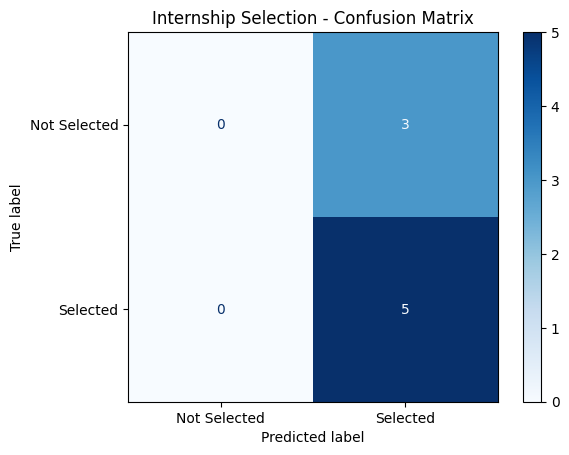

Confusion Matrix:
[[0 3]
 [0 5]]


In [18]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Selected', 'Selected']
)

disp.plot(cmap='Blues')
plt.title("Internship Selection - Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)

In [19]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})

feature_importance = feature_importance.sort_values(
    by='Coefficient',
    ascending=False
)

print(feature_importance)

                          Feature  Coefficient
2   prior_hackathon_participation     0.827131
4  Domain Applied_Cloud Computing     0.426939
7  Domain Applied_Web Development     0.420182
1                   has_portfolio     0.106921
3         statement_quality_score     0.025133
0               num_skills_listed    -0.190638
6     Domain Applied_Data Science    -0.363575
5   Domain Applied_Cyber Security    -0.676551


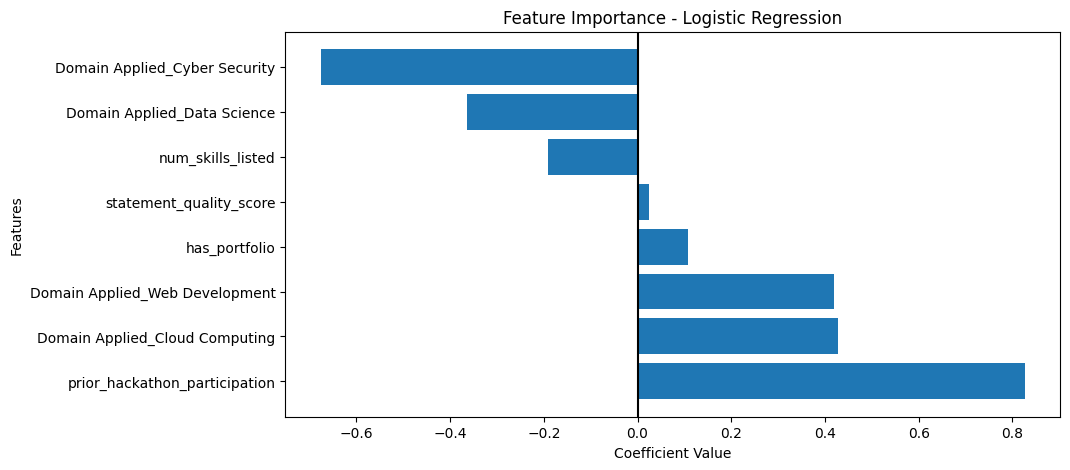

In [20]:
plt.figure(figsize=(10, 5))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Coefficient']
)

plt.xlabel("Coefficient Value")
plt.ylabel("Features")
plt.title("Feature Importance - Logistic Regression")
plt.axvline(x=0, color='black')
plt.show()

# Executive Summary – Internship Selection Prediction

## 1. Project Overview
This project uses Machine Learning to predict internship selection outcomes based on applicant information.

## 2. Dataset
The dataset contains applicant information and selection status. Four simulated features were added:
- Number of skills listed
- Portfolio availability
- Previous hackathon participation
- Statement quality score

## 3. Machine Learning Model
Logistic Regression was used to train the prediction model. The dataset was divided into 80% training data and 20% testing data.

## 4. Model Evaluation
The model was evaluated using:
- Accuracy
- Precision
- Recall
- Confusion Matrix

## 5. Feature Interpretation
Logistic Regression coefficients were used to understand how each feature influenced the model's predictions.

## 6. Limitations
- Some features were simulated rather than collected from real applicants.
- The dataset is small.
- Predictions may contain bias or errors.
- The model should support human decision-making, not replace human reviewers.

## 7. Conclusion
This project demonstrates how Machine Learning can be used to analyze applicant data and predict internship selection outcomes. It also provides practical experience in data preparation, model training, evaluation, and interpretation.

# Internship Selection Prediction

## Project Description
A Machine Learning project that predicts internship selection outcomes using applicant data.

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Scikit-learn
- Google Colab

## Project Workflow
1. Imported and explored the dataset.
2. Added four simulated applicant features.
3. Prepared the dataset and encoded categorical values.
4. Split the dataset into training and testing sets.
5. Trained a Logistic Regression model.
6. Evaluated the model using accuracy, precision, recall, and a confusion matrix.
7. Interpreted model coefficients.

## Simulated Features
- Number of skills listed
- Portfolio availability
- Previous hackathon participation
- Statement quality score

## Limitations
The additional features are simulated for educational purposes. The dataset is small, and the model is not suitable for real hiring decisions without further validation.

## Conclusion
This project demonstrates a basic Machine Learning workflow for predicting internship selection outcomes.

In [21]:
%%writefile README.md

# Internship Selection Prediction

## Project Description
A Machine Learning project that predicts internship selection outcomes using applicant data.

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Scikit-learn
- Google Colab

## Project Workflow
1. Imported and explored the dataset.
2. Added four simulated applicant features.
3. Prepared the dataset and encoded categorical values.
4. Split the dataset into training and testing sets.
5. Trained a Logistic Regression model.
6. Evaluated the model using accuracy, precision, recall, and a confusion matrix.
7. Interpreted model coefficients.

## Simulated Features
- Number of skills listed
- Portfolio availability
- Previous hackathon participation
- Statement quality score

## Limitations
The additional features are simulated for educational purposes. The dataset is small, and the model is not suitable for real hiring decisions without further validation.

## Conclusion
This project demonstrates a basic Machine Learning workflow for predicting internship selection outcomes.

Writing README.md
